# Active Subspaces of a Dynamic Earthquake Rupture Model: Seismic Moment and the Initial Stress Tensor

__Eric G. Daub__, Research Engineering Group, Alan Turing Institute, London, UK

__Hamid Arabnejad__, __Imran Mahmood__ and __Derek Groen__, Department of Computer Science, Brunel University London, London, UK

Notebook: Claude (Anthropic) for P. Constantine, 2026

<br>

**Summary.** Daub et al. [[1]](https://doi.org/10.1098/rsta.2020.0076) fit a Gaussian-process emulator to 30 two-dimensional dynamic rupture simulations of a rough fault (the open-source code fdfault) and use history matching to find the initial stresses consistent with an observed earthquake size. Here we estimate an active subspace of the size, the integrated final slip, over the paper's three uniform stress inputs, using the 30 runs printed in the paper's Tables 2 and 3 and the global quadratic (QPHD) estimator. The size depends mainly on one direction, dominated by the shear-to-normal stress ratio with a smaller part of the normal stress; a quadratic in that one active variable reproduces the 30 runs with a leave-one-out $R^2$ near 0.98.

It runs in Python 3 with numpy, scipy, matplotlib and the [active_subspaces](https://github.com/paulcon/active_subspaces) library, version 1.0 or later, in about ten seconds. It does not run the simulator; `DATA.md` says how the files were made and how to rerun fdfault.

### Active subspaces in brief

For a function $f(\mathbf x)$ of $m$ inputs with density $\rho$ on the normalized domain $[-1,1]^m$, the active subspace is spanned by the leading eigenvectors of $\mathbf C = \int \nabla f\,\nabla f^T\rho\,d\mathbf x = \mathbf W\Lambda\mathbf W^T$. A large gap after the $n$-th eigenvalue means that $f$ changes mostly along the $n$ directions $\mathbf W_1$, so $f(\mathbf x)\approx g(\mathbf W_1^T\mathbf x)$, and a *sufficient summary plot* of $f$ against the active variables $\mathbf y = \mathbf W_1^T\mathbf x$ shows the structure. Without gradients, $\mathbf C$ can be approximated from a least-squares fit of a global quadratic $q(\mathbf x)$ to samples of $f$, using $\nabla q$ in place of $\nabla f$. See Constantine (2015) [[2]](https://doi.org/10.1137/1.9781611973860).

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import active_subspaces as ac

SEED = 604                        # the only seed in this notebook (bootstrap)
t_start = time.perf_counter()

NAMES = ['sigma_yy', 'shear_to_normal', 'normal_ratio']
LABELS = [r'$\sigma_{yy}$', r'$\sigma_{xy}/\sigma_{yy}$', r'$\sigma_{xx}/\sigma_{yy}$']
LOWER = np.array([-120.0, 0.1, 0.9])    # paper Sec. 3(b), p. 8
UPPER = np.array([-80.0, 0.4, 1.1])
UNITS = ['MPa', '-', '-']
DESCR = ['fault-normal stress (negative in compression)', 'shear to normal stress ratio',
         'ratio of the two normal stress components']
space = ac.Uniform(LOWER, UPPER, names=NAMES)

### The model

fdfault [[3]](https://doi.org/10.1007/s10915-011-9485-3) solves the elastic wave equation in velocity-stress form for two-dimensional plane strain (paper Eq. (3.1)),

$$\rho\,\partial_t v_x = \partial_x\sigma_{xx}+\partial_y\sigma_{xy},\quad \rho\,\partial_t v_y = \partial_x\sigma_{xy}+\partial_y\sigma_{yy},$$
$$\partial_t\sigma_{xx} = \lambda(\partial_x v_x+\partial_y v_y)+2G\,\partial_x v_x,\quad \partial_t\sigma_{yy} = \lambda(\partial_x v_x+\partial_y v_y)+2G\,\partial_y v_y,\quad \partial_t\sigma_{xy} = G(\partial_y v_x+\partial_x v_y),$$

with high-order summation-by-parts differences, on a 32 km long fault with a rough, self-similar (fractal) profile whose RMS deviation from a plane is $10^{-2}$ of its length. Slip $U$ on the fault obeys slip-weakening friction [[4]](https://doi.org/10.1029/JB077i020p03796) (Eq. (3.2)),

$$\mu(U) = \begin{cases}(1-U/D_c)(\mu_s-\mu_d)+\mu_d, & U<D_c,\\ \mu_d, & U\ge D_c,\end{cases}$$

with the fixed values of the paper's Table 1: $\lambda = G = 32.04$ GPa, $\mu_s = 0.7$, $\mu_d = 0.2$, $D_c = 0.8$ m, and $\rho = 2.68\times10^3$ kg m$^{-3}$. (Neither the authors' set-up, fabmogp v1.0 `create_problem`, nor the adaptation used here sets a material, so fdfault's default applies, and its `material` class defaults to $\rho = 2.67\times10^3$ kg m$^{-3}$ (`fdfault/python/fdfault/material.py`, line 54). That code default is the evidence that the paper's runs used 2.67. The reruns below use 2.67 and reproduce the printed sizes, but no run at 2.68 was made, so they do not tell the two values apart.) Rupture is nucleated over a 4 km patch at the centre of the fault by raising the shear stress to failure, and strong barriers ($\mu_s = 10^4$) 2 km from each end stop it. The grid is 401 × 302 points, with 800 time steps at a CFL number of 0.3. The fault profile is one fixed realization (seed 18749 in the authors' code).

**Inputs.** The uniform initial stress tensor is set by three inputs, each independent and uniform (paper Sec. 3(b), p. 8): $\sigma_{xx} = (\sigma_{xx}/\sigma_{yy})\,\sigma_{yy}$ and $\sigma_{xy} = -(\sigma_{xy}/\sigma_{yy})\,\sigma_{yy}$, so the shear stress is positive. The table below is printed from the bounds in the code cell above.

**Quantity of interest.** The final slip integrated along the fault with Simpson's rule, in m km (paper Sec. 5(a), p. 10). With a fixed shear modulus in 2-D it is proportional to the seismic moment, the size of the earthquake.

**Data.** The paper's two Latin hypercube designs, 20 training runs (Table 2) and 10 validation runs (Table 3), 30 runs in all. `paper_tables.csv` holds the printed values; `design_inputs.csv` holds the same inputs at full precision, redrawn from the seeds in the authors' workflow (they round to every printed value). `fdfault_reruns.csv` holds five of the runs repeated here with fdfault v1.0.1.

In [2]:
print(f"{'name':16s} {'units':5s} {'lower':>7s} {'upper':>7s}  description")
for nm, u, lo, hi, d in zip(NAMES, UNITS, LOWER, UPPER, DESCR):
    print(f'{nm:16s} {u:5s} {lo:7.1f} {hi:7.1f}  {d}')

name             units   lower   upper  description
sigma_yy         MPa    -120.0   -80.0  fault-normal stress (negative in compression)
shear_to_normal  -         0.1     0.4  shear to normal stress ratio
normal_ratio     -         0.9     1.1  ratio of the two normal stress components


### Load the data

In [3]:
tab = np.loadtxt('paper_tables.csv', delimiter=',')          # table, row, 3 inputs (printed), moment
X = np.loadtxt('design_inputs.csv', delimiter=',')[:, 3:]    # (30, 3) full-precision inputs, physical units
f = tab[:, 5]                                                # (30,) integrated final slip, m km
train = tab[:, 0] == 2                                       # Table 2 rows; Table 3 rows are validation
rr = np.loadtxt('fdfault_reruns.csv', delimiter=',', ndmin=2)  # fdfault reruns of five rows
print(f'X {X.shape}, f {f.shape} ({train.sum()} training + {(~train).sum()} validation), reruns {rr.shape}')
print(f'f from {f.min():.2f} to {f.max():.2f} m km; all inputs inside the box: {bool(np.all((X >= LOWER) & (X <= UPPER)))}')
print(f'full-precision inputs vs printed: max |difference| {np.abs(X - tab[:, 2:5]).max(axis=0)} (rounding)')

X (30, 3), f (30,) (20 training + 10 validation), reruns (5, 7)
f from 29.24 to 296.45 m km; all inputs inside the box: True
full-precision inputs vs printed: max |difference| [0.00495515 0.00048944 0.00048142] (rounding)


**Check against the simulator.** We reran five of the 30 runs with fdfault (`DATA.md`). The cell below compares the rerun sizes with the printed ones.

In [4]:
print(' row  table  printed (m km)  fdfault rerun (m km)  |diff|  run time (s)')
for r in rr:
    k = int(r[0]) - 1
    print(f'{k + 1:4d}  {int(tab[k, 0]):3d}/{int(tab[k, 1]):<2d}  {f[k]:10.2f}  {r[4]:20.6f}  {abs(r[4] - f[k]):7.4f}  {r[6]:8.0f}')
print(f'largest |rerun - printed| = {np.max(np.abs(rr[:, 4] - f[rr[:, 0].astype(int) - 1])):.4f} m km '
      f'(printed to 0.01; rounding alone allows 0.005)')

 row  table  printed (m km)  fdfault rerun (m km)  |diff|  run time (s)
   1    2/1       213.37            213.366643   0.0034       246
  11    2/11      296.45            296.449618   0.0004       196
  13    2/13       29.24             29.239023   0.0010       226
  21    3/1        62.21             62.212413   0.0024       165
  29    3/9       253.26            253.263079   0.0031       354
largest |rerun - printed| = 0.0034 m km (printed to 0.01; rounding alone allows 0.005)


The five reruns agree with the printed sizes to within 0.0034 m km, inside the 0.005 m km that rounding to two decimals allows, for sizes from 29.24 to 296.45 m km and for runs from both designs. So the printed values are outputs of this simulator and this set-up. Each rerun took 165–354 s on one process of a shared two-CPU container, which is why we use the 30 published runs and do not draw a larger design here.

### Estimate the subspace

There are no gradients, and 30 runs of a 3-input function are too few for local linear gradients, so we use the global quadratic estimator (`"qphd"`, related to the principal Hessian directions of Li [[5]](https://doi.org/10.1080/01621459.1992.10476258)): a least-squares quadratic $q(\mathbf x) = c + \mathbf g^T\mathbf x + \tfrac12\mathbf x^T\mathbf H\mathbf x$ in the normalized inputs (10 coefficients from 30 runs, 3 per coefficient), and $\hat{\mathbf C} = \mathbf g\mathbf g^T + \mathbf H\Sigma\mathbf H$ with $\Sigma = \tfrac13\mathbf I$, the covariance of the uniform density on $[-1,1]^3$; this is the average of $\nabla q\nabla q^T$ over the box. v1 warns that the estimator's theory assumes Gaussian inputs; the formula above is still the exact average over the uniform box, so we suppress that warning. The bootstrap (500 replicates) resamples the 30 runs. As cross-checks we compute the linear (OLS) direction and the QPHD estimate from the 20 training runs alone.

**What these numbers describe.** $\hat{\mathbf C}$ is computed from the fitted quadratic $q$, not from $f$. The quadratic leaves a residual (printed below), and the paper calls the response non-stationary, with steep transitions between rupture arrest and propagation (Fig. 3 caption, p. 12; p. 13). So $\lambda_2$, $\lambda_3$ and $\mathbf w_2$ are properties of the quadratic; whether $f$ itself has a second direction cannot be tested with 30 runs. The bootstrap resamples the 30 runs and refits the 10 coefficients, so its intervals measure only the resampling variability of that fit, and each replicate holds fewer distinct runs than 30 (counted below). The support for $n = 1$ is the agreement of several checks: the bootstrap, a leave-one-out jackknife of $\mathbf w_1$ (after the eigenvalue plot), the OLS direction, and QPHD from the 20 training runs alone.

Inputs are passed in physical units; v1 maps each to $[-1,1]$ by its own range (the same scaling for all three, since all are uniform).

In [5]:
import warnings
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('ignore', ac.ValidityWarning)
    warnings.simplefilter('always', ac.AccuracyWarning)
    sub = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', nboot=500,
                             bootstrap_vectors=2, rng=SEED)
    sub_ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1)
    sub_tr = ac.active_subspace(space=space, X=X[train], f=f[train], estimator='qphd')
    # the rows each bootstrap replicate drew: v1 gives replicate b child b of SeedSequence(SEED)
    kids = np.random.default_rng(np.random.SeedSequence(SEED)).spawn(500)
    boot_rows = [k.integers(0, len(f), size=len(f)) for k in kids]
    lam_rep0 = ac.active_subspace(space=space, X=X[boot_rows[0]], f=f[boot_rows[0]], estimator='qphd').eigenvalues
for w in caught:
    print('AccuracyWarning:', str(w.message).split(';')[0])
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=2)   # f increases along w1 and w2
lam = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print(f'QPHD eigenvalues: {np.array2string(lam, precision=4)}; dimension from the gap rule n = {sub.n}')
print(f'95% bootstrap intervals: ' + ', '.join(f'[{a:.3g}, {b:.3g}]' for a, b in ci.T))
print(f'lambda1/lambda2 = {lam[0] / lam[1]:.1f}, lambda2/lambda3 = {lam[1] / lam[2]:.1f}; '
      f'lambda1 holds {lam[0] / lam.sum():.1%} of the trace')
ci_ratio = ac.bootstrap_interval(sub.bootstrap_eigenvalues[:, 0] / sub.bootstrap_eigenvalues[:, 1])[:, 0]
print(f'95% bootstrap interval of lambda1/lambda2: [{ci_ratio[0]:.1f}, {ci_ratio[1]:.1f}]')
quad = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=2)   # the quadratic behind C
res = ac.predict(quad, X) - f
print(f'the fitted quadratic q, in sample: residual RMS {np.sqrt(np.mean(res ** 2)):.1f} m km, '
      f'R^2 = {1 - np.sum(res ** 2) / np.sum((f - f.mean()) ** 2):.3f}')
n_distinct = np.array([np.unique(r).size for r in boot_rows])
print(f'distinct runs in a bootstrap replicate: median {np.median(n_distinct):.0f}, min {n_distinct.min()}, '
      f'max {n_distinct.max()} of 30 (the quadratic has 10 coefficients); '
      f'replicate 0 refitted from these rows matches the stored one: {np.allclose(lam_rep0, sub.bootstrap_eigenvalues[0])}')
w1, w2 = sub.W[:, 0], sub.W[:, 1]
print('w1 =', np.round(w1, 3), '  w2 =', np.round(w2, 3))
print('OLS direction =', np.round(sub_ols.W[:, 0], 3), f'  |w1 . w_ols| = {abs(w1 @ sub_ols.W[:, 0]):.4f}')
print('QPHD, 20 training runs only: w1 =', np.round(sub_tr.W[:, 0], 3),
      f' |w1 . w1(train)| = {abs(w1 @ sub_tr.W[:, 0]):.4f}, '
      f'lambda1/lambda2 = {sub_tr.eigenvalues[0] / sub_tr.eigenvalues[1]:.1f}')

QPHD eigenvalues: [1.9871e+04 4.5617e+02 1.9252e+01]; dimension from the gap rule n = 1
95% bootstrap intervals: [1.79e+04, 2.39e+04], [229, 1.66e+03], [5.09, 372]
lambda1/lambda2 = 43.6, lambda2/lambda3 = 23.7; lambda1 holds 97.7% of the trace
95% bootstrap interval of lambda1/lambda2: [12.1, 87.3]
the fitted quadratic q, in sample: residual RMS 7.4 m km, R^2 = 0.991
distinct runs in a bootstrap replicate: median 19, min 14, max 25 of 30 (the quadratic has 10 coefficients); replicate 0 refitted from these rows matches the stored one: True
w1 = [-0.214  0.977 -0.004]   w2 = [0.96  0.211 0.185]
OLS direction = [-0.174  0.985  0.023]   |w1 . w_ols| = 0.9988
QPHD, 20 training runs only: w1 = [-0.196  0.98   0.038]  |w1 . w1(train)| = 0.9989, lambda1/lambda2 = 31.0


### Results

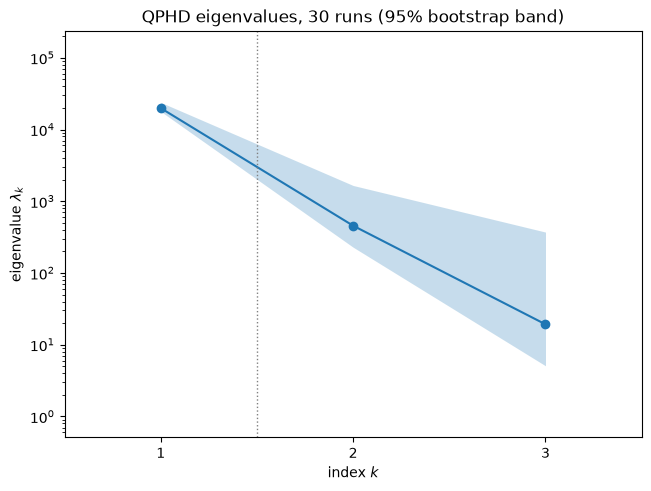

In [6]:
fig, ax = ac.plotting.plot_eigenvalues(sub)
ax.set_title('QPHD eigenvalues, 30 runs (95% bootstrap band)')
fig

The first eigenvalue, $1.99\times10^4$, is 43.6 times the second (95% bootstrap interval of the ratio [12.1, 87.3]), and the second is 23.7 times the third; $\lambda_1$ is 97.7% of the trace. The 95% bootstrap intervals of $\lambda_1$, [1.79e4, 2.39e4], and $\lambda_2$, [229, 1.66e3], are far apart, and the gap rule picks $n = 1$. These are eigenvalues of the fitted quadratic, which matches the 30 runs with in-sample $R^2 = 0.991$ and a residual RMS of 7.4 m km: $\lambda_2$ and $\lambda_3$ say what the quadratic does off $\mathbf w_1$, not what $f$ does. The intervals come from replicates with a median of 19 distinct runs (minimum 14), not many more than the quadratic's 10 coefficients, so they describe the variability of that fit; those of $\lambda_2$ and $\lambda_3$ are wide and overlap.

jackknife, one run left out at a time (30 fits): min |w1 . w1(-i)| = 0.99977; lambda1/lambda2 from 35.6 to 53.1; n from the gap rule: [1]
mean bootstrap subspace distance for n = 1, 2: [0.037 0.271]


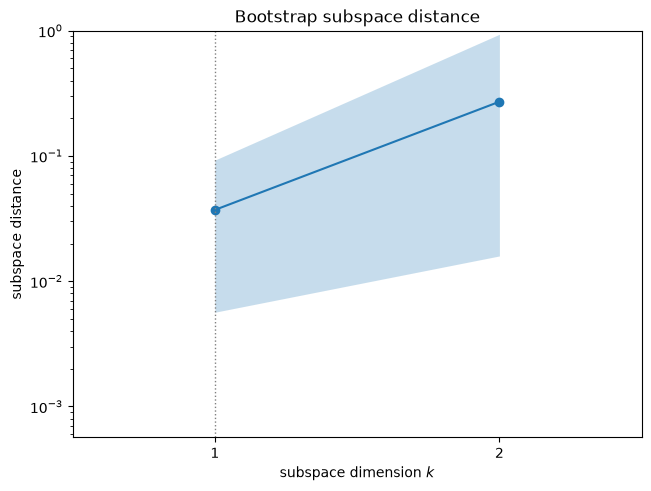

In [7]:
# leave-one-out jackknife: QPHD on 29 runs, 30 times
jk = []
with warnings.catch_warnings():
    warnings.simplefilter('ignore', ac.ValidityWarning)
    for i in range(len(f)):
        keep = np.arange(len(f)) != i
        jk.append(ac.active_subspace(space=space, X=X[keep], f=f[keep], estimator='qphd'))
jk_dot = np.array([abs(s.W[:, 0] @ w1) for s in jk])
jk_ratio = np.array([s.eigenvalues[0] / s.eigenvalues[1] for s in jk])
print(f'jackknife, one run left out at a time (30 fits): min |w1 . w1(-i)| = {jk_dot.min():.5f}; '
      f'lambda1/lambda2 from {jk_ratio.min():.1f} to {jk_ratio.max():.1f}; n from the gap rule: {sorted({s.n for s in jk})}')
fig, ax = ac.plotting.plot_subspace_errors(sub)
ax.set_title('Bootstrap subspace distance')
dist = sub.bootstrap_distances.mean(axis=0)
print('mean bootstrap subspace distance for n = 1, 2:', np.round(dist, 3))
fig

The mean bootstrap distance between the estimated and resampled subspaces is 0.037 for $n = 1$ and 0.271 for $n = 2$: the first direction is well determined by 30 runs, the second is not (the `AccuracyWarning` above says the same about the replicates of $\mathbf w_2$). The jackknife agrees: leaving out any one of the 30 runs moves $\mathbf w_1$ by at most $|\mathbf w_1\cdot\mathbf w_1^{(-i)}| = 0.99977$, and $\lambda_1/\lambda_2$ stays between 35.6 and 53.1, inside the bootstrap interval [12.1, 87.3].

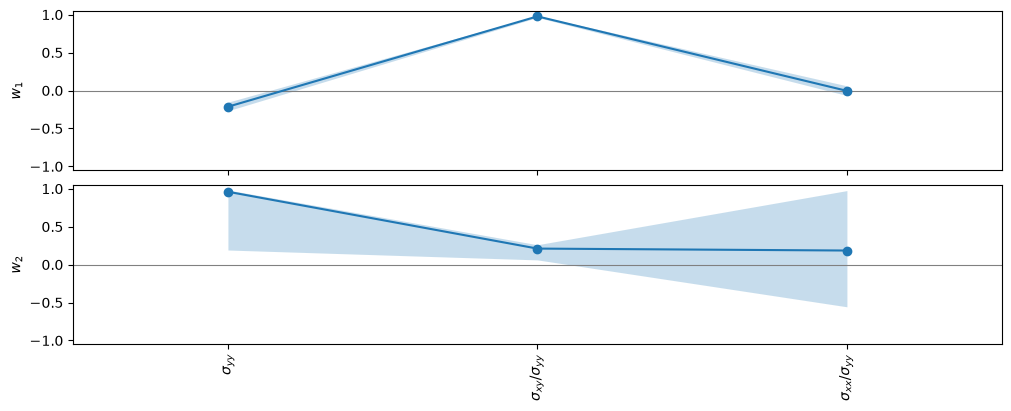

In [8]:
fig, axes = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=LABELS, interval='percentile', figsize=(10, 4))
fig

$\mathbf w_1 = (-0.214, 0.977, -0.004)$ in the order $(\sigma_{yy}, \sigma_{xy}/\sigma_{yy}, \sigma_{xx}/\sigma_{yy})$. The shear to normal stress ratio dominates, the normal stress has a smaller weight of opposite sign, and the ratio of the normal stress components has almost none. Since $\sigma_{yy} < 0$, the size grows with the shear ratio and with the magnitude of the compressive normal stress, which at a fixed ratio scales up the initial shear stress. The linear (OLS) direction, $(-0.174, 0.985, 0.023)$, and the QPHD direction from the 20 training runs alone agree with $\mathbf w_1$ to $|\mathbf w\cdot\mathbf w_1| = 0.9988$ and $0.9989$. The second eigenvector is mostly $\sigma_{yy}$, with wide bootstrap bands.

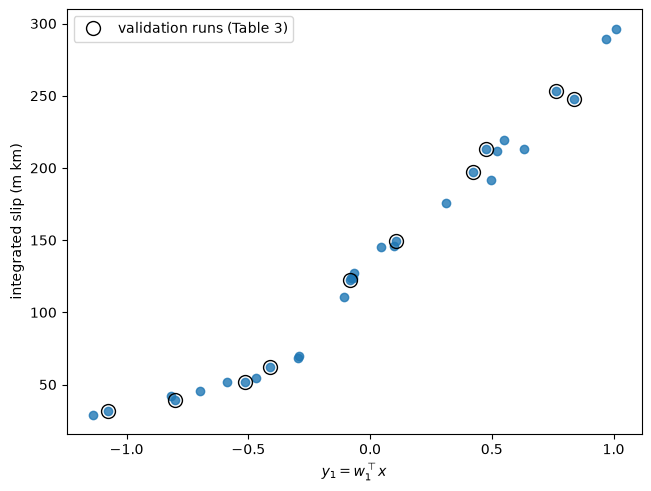

In [9]:
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='integrated slip (m km)')
y = space.to_normalized(X) @ w1
ax.plot(y[~train], f[~train], 'o', mfc='none', mec='k', ms=10, label='validation runs (Table 3)')
ax.legend()
fig

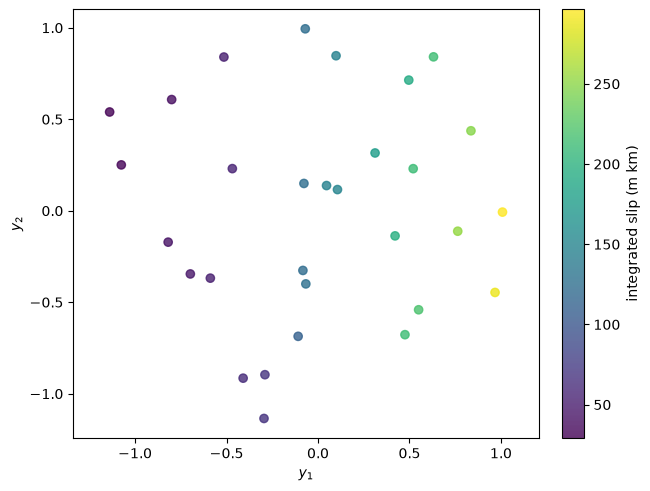

In [10]:
fig, ax = ac.plotting.plot_sufficient_summary(ac.with_dimension(sub, 2), X=X, f=f, dims=2,
                                              qoi_label='integrated slip (m km)')
fig

Along $y_1$ the size rises monotonically from 29 to 296 m km, steepest in the middle of the range, and the ten validation runs (circled) lie on the same curve as the training runs. In the two-dimensional plot the colour changes along $y_1$ and hardly along $y_2$, as expected when $\lambda_2$ is about 2% of the trace of the quadratic's $\hat{\mathbf C}$.

### A surrogate on the active variable

We fit polynomials in $y_1 = \mathbf w_1^T\mathbf x$ (and in $(y_1, y_2)$) and report the leave-one-out $R^2$; for reference, also a full quadratic in all three normalized inputs. These LOO values keep $\mathbf w_1$ fixed from all 30 runs; for the quadratic in $y_1$ we also compute a nested LOO that re-estimates $\mathbf w_1$ in each fold (from the jackknife fits above). For a clean validation, the direction and the quadratic are both estimated from the 20 training runs (Table 2) only, and scored on the 10 validation runs (Table 3), as in the paper.

1 active variable(s), degree 1: LOO R^2 = 0.9454
1 active variable(s), degree 2: LOO R^2 = 0.9792
1 active variable(s), degree 3: LOO R^2 = 0.9847
2 active variable(s), degree 2: LOO R^2 = 0.9855
full quadratic in all 3 inputs: LOO R^2 = 0.9787
nested LOO R^2, quadratic in y1 with w1 re-estimated in each fold: 0.9770
quadratic in y1, w1 and fit from the 20 training runs only: validation RMSE 13.6 m km, largest |error| 20.6 m km
full quadratic in all 3 inputs, fitted to the 20 training runs: validation RMSE 17.4 m km, largest |error| 37.7 m km


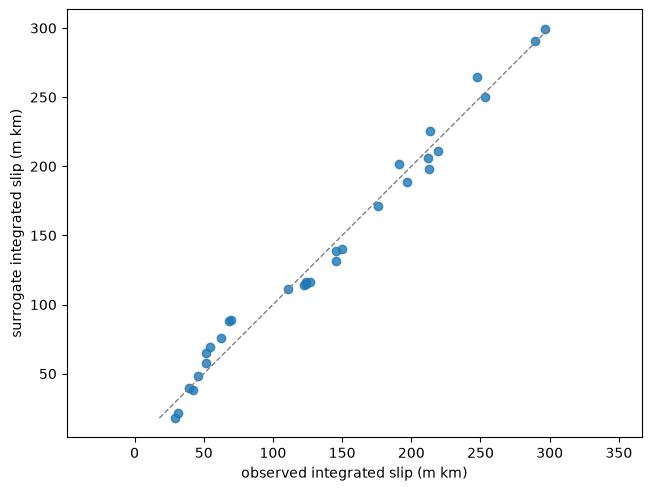

In [11]:
fits = {}
for n, deg in [(1, 1), (1, 2), (1, 3), (2, 2)]:
    s = ac.fit_surrogate(X=X, f=f, space=space, subspace=ac.with_dimension(sub, n), kind='poly', degree=deg)
    fits[(n, deg)] = s
    print(f'{n} active variable(s), degree {deg}: LOO R^2 = {s.loo_r_squared:.4f}')
full = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=2)
print(f'full quadratic in all 3 inputs: LOO R^2 = {full.loo_r_squared:.4f}')
# nested LOO: w1 re-estimated without run i (jackknife fits), quadratic in y1 refitted, run i predicted
e_nest = np.array([float(ac.predict(ac.fit_surrogate(X=np.delete(X, i, 0), f=np.delete(f, i), space=space,
                                                     subspace=ac.with_dimension(s, 1), kind='poly', degree=2),
                                    X[i:i + 1])[0]) - f[i] for i, s in enumerate(jk)])
print(f'nested LOO R^2, quadratic in y1 with w1 re-estimated in each fold: '
      f'{1 - np.sum(e_nest ** 2) / np.sum((f - f.mean()) ** 2):.4f}')
# clean validation: w1 (sub_tr) and the quadratic both from the 20 training runs; scored on the 10 validation runs
s_tr = ac.fit_surrogate(X=X[train], f=f[train], space=space, subspace=ac.with_dimension(sub_tr, 1), kind='poly', degree=2)
err = ac.predict(s_tr, X[~train]) - f[~train]
print(f'quadratic in y1, w1 and fit from the 20 training runs only: validation RMSE {np.sqrt(np.mean(err ** 2)):.1f} m km, '
      f'largest |error| {np.max(np.abs(err)):.1f} m km')
full_tr = ac.fit_surrogate(X=X[train], f=f[train], space=space, subspace=None, kind='poly', degree=2)
err_full = ac.predict(full_tr, X[~train]) - f[~train]
print(f'full quadratic in all 3 inputs, fitted to the 20 training runs: validation RMSE '
      f'{np.sqrt(np.mean(err_full ** 2)):.1f} m km, largest |error| {np.max(np.abs(err_full)):.1f} m km')
fig, ax = ac.plotting.plot_surrogate_fit(fits[(1, 2)], X=X, f=f, qoi_label='integrated slip (m km)')
fig

A quadratic in the single active variable, three coefficients, has leave-one-out $R^2 = 0.979$, the same as the full quadratic in all three inputs with ten coefficients (0.979); a line gives 0.945, a cubic 0.985, and a quadratic in $(y_1, y_2)$ 0.986. Re-estimating $\mathbf w_1$ inside each leave-one-out fold lowers the quadratic's value only to 0.977. In the clean validation, with $\mathbf w_1$ and the quadratic both estimated from the 20 training runs, so that the 10 validation runs play no part in the fit, the quadratic in $y_1$ predicts the validation runs with an RMS error of 13.6 m km and a largest error of 20.6 m km. The full quadratic in all three inputs, fitted to the same 20 runs, does worse on them: 17.4 m km RMS, largest 37.7 m km.

### Comparison with the paper

The paper reports no active subspace. It reports the emulator's correlation lengths $\theta_i$ (p. 10), where a short length means a strong dependence, and says that the output is most sensitive to the shear to normal stress ratio and normal stress and not highly sensitive to the normal stress ratio (Fig. 3 caption, p. 12; p. 13). Its history-matching result (p. 13, Fig. 4) gives a level set: for an observed size of 58 m km, the shear to normal ratio is "around 0.16" at high compressive normal stress and "near 0.2" at lower normal stress. A level set of a ridge function $g(\mathbf w_1^T\mathbf x)$ is orthogonal to $\mathbf w_1$, so those two values imply a direction, which we compare with $\mathbf w_1$, and with the 58 m km level set of the full quadratic.

In [12]:
from scipy.optimize import brentq
theta = np.array([43.755, 0.109, 0.599])           # paper p. 10, physical units
half = (UPPER - LOWER) / 2
print('correlation length / half-range (normalized):', np.round(theta / half, 2))

# direction implied by the NROY curve of p. 13: (sigma_yy, ratio) = (-120, 0.16) and (-80, 0.20)
a, b = space.to_normalized(np.array([[-120, .16, 1.], [-80, .20, 1.]]))
t = (b - a)[:2]
n_impl = np.array([-t[1], t[0]]) / np.hypot(*t)
n_impl *= np.sign(n_impl[1])
print('direction normal to the paper\'s 58 m km curve (sigma_yy, shear/normal):', np.round(n_impl, 3),
      f' ratio |w_sigma / w_shear| = {abs(n_impl[0] / n_impl[1]):.3f}')
print(f'w1 here: ratio |w_sigma / w_shear| = {abs(w1[0] / w1[1]):.3f}')

# the 58 m km level set of the full quadratic, at sigma_xx/sigma_yy = 1
def ratio_at(s_yy, level=58.0):
    g = lambda r: float(ac.predict(full, np.array([[s_yy, r, 1.0]]))[0]) - level
    return brentq(g, 0.1, 0.3)
print('full quadratic, 58 m km level set: shear/normal = '
      + ', '.join(f'{ratio_at(s):.3f} at {s:.0f} MPa' for s in (-120, -100, -80)))

correlation length / half-range (normalized): [2.19 0.73 5.99]
direction normal to the paper's 58 m km curve (sigma_yy, shear/normal): [-0.132  0.991]  ratio |w_sigma / w_shear| = 0.133
w1 here: ratio |w_sigma / w_shear| = 0.219
full quadratic, 58 m km level set: shear/normal = 0.158 at -120 MPa, 0.154 at -100 MPa, 0.184 at -80 MPa


Divided by the half-range of each input, the emulator's correlation lengths are 0.73 (shear ratio), 2.19 (normal stress) and 5.99 (normal stress ratio): the same order of importance as $|\mathbf w_1|$ = 0.977, 0.214, 0.004. The two values the paper gives for its 58 m km curve imply a normal direction $(-0.132, 0.991)$ in $(\sigma_{yy}, \sigma_{xy}/\sigma_{yy})$: the same signs and the same dominant input as $\mathbf w_1$, with a smaller relative weight on the normal stress (0.133 against 0.219). The full quadratic's 58 m km level set gives ratios 0.158 at −120 MPa and 0.184 at −80 MPa, against the paper's "around 0.16" and "near 0.2"; it dips to 0.154 at −100 MPa, which the paper does not describe and which may be an artefact of the quadratic. Both comparisons are local to the 58 m km level, near the small end of the data, and the paper's values are approximate, so they do not test $\mathbf w_1$ precisely.

| quantity | paper | notebook |
|---|---|---|
| most influential input | shear to normal stress ratio (pp. 12–13) | shear to normal ratio, $w_{1,2} = 0.977$ |
| second | normal stress (Fig. 3b, Fig. 4) | normal stress, $w_{1,1} = -0.214$ |
| least | normal stress ratio, "not highly sensitive" (Fig. 3 caption) | $w_{1,3} = -0.004$ |
| GP correlation length / half-range | 2.19, 0.73, 5.99 (from 43.755, 0.109, 0.599, p. 10) | not computed (no GP); ordering matches $\lvert\mathbf w_1\rvert$ |
| direction normal to the 58 m km curve | $(-0.13, 0.99)$, from the ratios on p. 13 | $\mathbf w_1$: $(-0.21, 0.98)$ |
| ratio on the 58 m km curve at −120 / −80 MPa | ≈ 0.16 / ≈ 0.2 (p. 13) | 0.158 / 0.184 (full quadratic) |
| range of the size | 35 to ≈ 300 m km (text, p. 10); 29.24 to 296.45 (Tables 2–3) | 29.24 to 296.45 m km (same 30 runs) |
| reruns of printed sizes | not reported | 5 of 5 within 0.0034 m km |
| eigenvalues, active subspace | not reported | $\lambda_1/\lambda_2 = 43.6$ (bootstrap [12.1, 87.3]; jackknife 35.6–53.1), $\lambda_2/\lambda_3 = 23.7$ (of the fitted quadratic), $n = 1$ |
| surrogate validation on Table 3 | GP: 8 of 10 within 3 standard errors (Fig. 3a) | quadratic in $y_1$, $\mathbf w_1$ and fit from the 20 training runs: RMS error 13.6 m km, largest 20.6 m km |

In [13]:
print(f'Total run time: {time.perf_counter() - t_start:.1f} s')

Total run time: 5.3 s


### References

[1] E. G. Daub, H. Arabnejad, I. Mahmood and D. Groen. Uncertainty quantification of dynamic earthquake rupture simulations. *Phil. Trans. R. Soc. A* 379(2197):20200076, 2021. [doi:10.1098/rsta.2020.0076](https://doi.org/10.1098/rsta.2020.0076)

[2] P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM, Philadelphia, 2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860)

[3] J. E. Kozdon, E. M. Dunham and J. Nordström. Interaction of waves with frictional interfaces using summation-by-parts difference operators: weak enforcement of nonlinear boundary conditions. *J. Sci. Comput.* 50(2):341–367, 2012. [doi:10.1007/s10915-011-9485-3](https://doi.org/10.1007/s10915-011-9485-3)

[4] Y. Ida. Cohesive force across the tip of a longitudinal-shear crack and Griffith's specific surface energy. *J. Geophys. Res.* 77(20):3796–3805, 1972. [doi:10.1029/JB077i020p03796](https://doi.org/10.1029/JB077i020p03796)

[5] K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another application of Stein's lemma. *J. Amer. Statist. Assoc.* 87(420):1025–1039, 1992. [doi:10.1080/01621459.1992.10476258](https://doi.org/10.1080/01621459.1992.10476258)

Software: fdfault v1.0.1 (https://github.com/edaub/fdfault, MIT), fabmogp v1.0 (https://github.com/alan-turing-institute/fabmogp, MIT), and the paper's workflow (https://github.com/alan-turing-institute/fabmogp_paper, MIT).

### Acknowledgments

From the paper: E.G.D. received support from EPSRC grant no. EP/N510129/1 to the Alan Turing Institute. I.M. and D.G. received funding from the European Union Horizon 2020 research and innovation programme under grant agreements no. 800925 (VECMA) and 824115 (HiDALGO).